In [93]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras

import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2
import time




bloco = 0
r_seed = 42

WORKDIR = 'C:/Users/thewr/git/LSTM_giroscopio_acelerometro.git/'
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/Code/DataPrep/"+data_hora

In [94]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [95]:
pd.set_option("display.precision", 9)

In [96]:
## get dataset

# select only sensor data from smart watches
data = pd.read_csv('activity_recognition_data_watch_concat_by_comparacao_grupos.csv',dtype={"value": "float64"})

In [97]:
data.head(10)

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904
5,1600,0,90426955696641,4.6615110,0.16968904,9.6846950,90427005196641,-0.101574294,1.08268610,-0.134192960
6,1600,0,90427005196641,6.1459160,0.83288294,11.0039010,90427054696641,-0.677882400,1.17642930,-0.211957260
7,1600,0,90427054696641,7.2592196,-0.79278004,11.4851350,90427104196641,-0.163359630,1.01983550,0.303630700
8,1600,0,90427104196641,7.3549876,-2.53575900,11.4540110,90427153696641,0.412948430,0.99000800,0.994987300
9,1600,0,90427153696641,7.3190746,-2.70095870,11.4611930,90427203196641,0.286181960,0.78654253,1.180343400


In [98]:
data.isnull().sum()

pessoa_x              0
atividade             0
tempo_acelerômetro    0
acelerômetro_x        0
acelerômetro_Y        0
acelerômetro_Z        0
tempo_gyro            0
giroscópio_x          0
giroscópio_Y          0
giroscópio_Z          0
dtype: int64

In [99]:
data.shape

(3441622, 10)

In [100]:
#remove the null class
data=data.dropna()

In [101]:
data=data[data["pessoa_x"]!=1629]
data.shape


(3311884, 10)

In [102]:
data=data[~(data["pessoa_x"].isin(np.arange(1636,1640)))]

In [103]:
data.pessoa_x.value_counts().count()

46

In [104]:
data.shape

(3028319, 10)

# **Data Exploration**

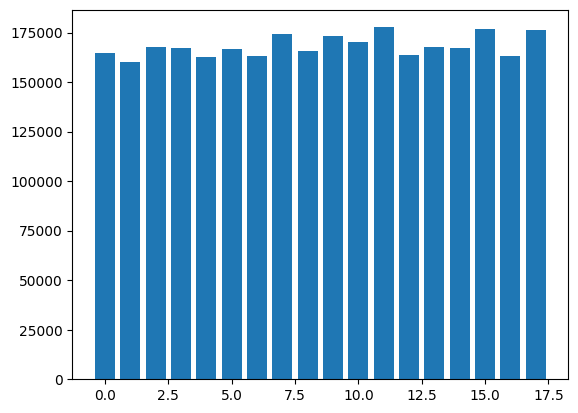

In [105]:
## the distribution of output classes
plt.bar(data["atividade"].value_counts().index, data["atividade"].value_counts().values)
plt.show()

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

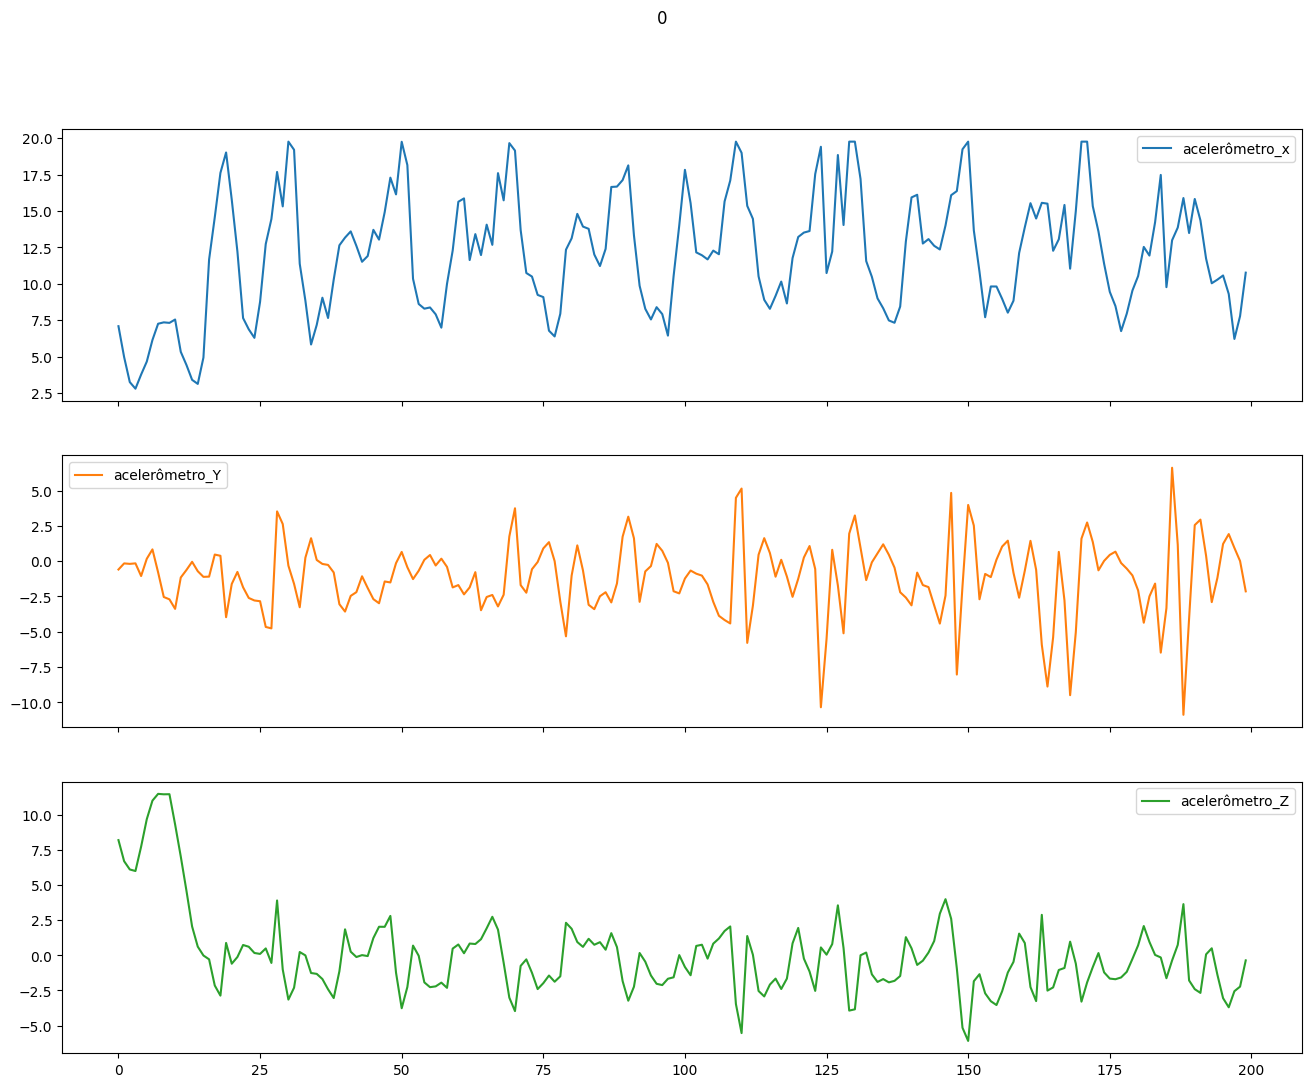

In [106]:
## x,y,z vaues for activity 'sit' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['acelerômetro_x','acelerômetro_Y','acelerômetro_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

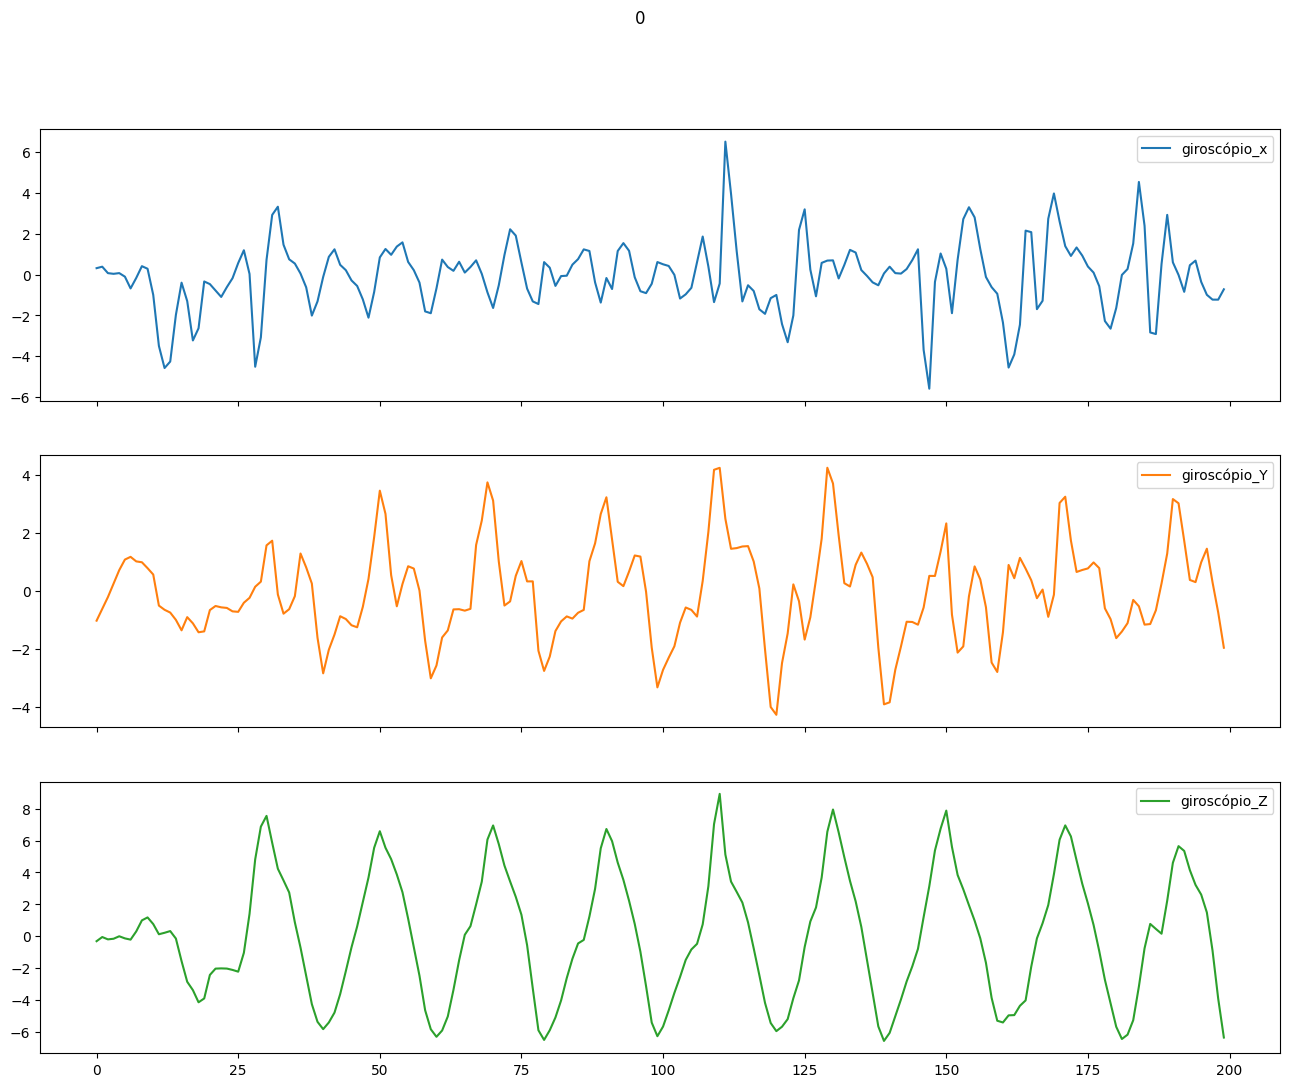

In [107]:
## x,y,z vaues for activity 'stand' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['giroscópio_x','giroscópio_Y','giroscópio_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

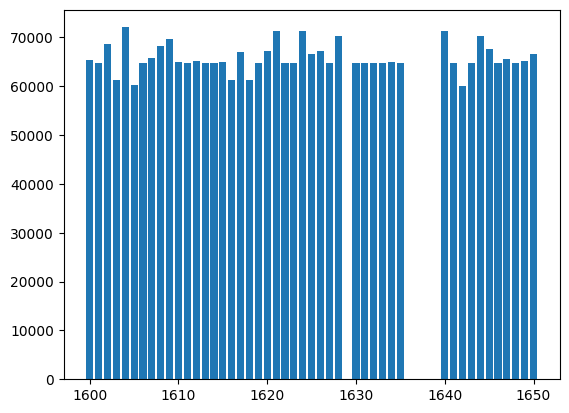

In [108]:
## number of events per user

plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [109]:
#selecting only activities 0 to 3
data = data[data["atividade"].isin([0,1,2,3])]

In [110]:
data = data.reset_index(drop=True)

In [111]:
data.shape

(659886, 10)

In [112]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904


In [113]:
data.shape

(659886, 10)

In [114]:
data.tail(1)

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
659885,1650,3,2425320882941187,-0.8276456,0.9059061,9.7657995,2425320932928957,0.00203066,0.005392901,0.011318169


# **Models**

In [115]:
def split_indices_for_kfold(validation_sets):
    split_indices = np.empty((9, 2))
    position = 0
    for set in validation_sets:
        start_validation_index = data[(data['pessoa_x'].isin(set))].head(1).index[0]
        end_validation_index = data[(data['pessoa_x'].isin(set))].tail(1).index[0]
        split_indices[position]= [start_validation_index,end_validation_index]
        position = position + 1
    return split_indices       


In [116]:
data.tail(1)

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
659885,1650,3,2425320882941187,-0.8276456,0.9059061,9.7657995,2425320932928957,0.00203066,0.005392901,0.011318169


In [117]:




validation_set1=np.arange(1646,1651)
validation_set2=np.arange(1640,1646)
validation_set3=np.arange(1600,1605)
validation_set4=np.arange(1605,1610)
validation_set5=np.arange(1610,1615)
validation_set6=np.arange(1615,1620)
validation_set7=np.arange(1620,1625)
validation_set8=np.arange(1625,1631)
validation_set9=np.arange(1631,1636)
combined_validation_sets = [validation_set1,
validation_set2,validation_set3,validation_set4,validation_set5,validation_set6,validation_set7,validation_set8, validation_set9, ]
split_indices = split_indices_for_kfold(combined_validation_sets)

In [118]:
print(split_indices[0])

[585455. 659885.]


In [119]:
for elem1,elem2 in split_indices:    
        print(f"{elem1}-{elem2} -- total percentual={(elem2-elem1)/data.shape[0]}")    

585455.0-659885.0 -- total percentual=0.11279220956347005
501516.0-585454.0 -- total percentual=0.1272007589189648
0.0-72050.0 -- total percentual=0.10918552598479131
72051.0-140500.0 -- total percentual=0.10372852280545428
140501.0-212560.0 -- total percentual=0.10919916470420649
212561.0-281004.0 -- total percentual=0.10371943032584416
281005.0-357367.0 -- total percentual=0.11571998799792692
357368.0-429450.0 -- total percentual=0.10923401920937859
429451.0-501515.0 -- total percentual=0.10920674177054825


In [120]:
def delete_segments_not_fully_filled(df_data_windowed,df_label_windowed):
    indexes = np.where(df_label_windowed == -1)[0]
    unique_arr = np.unique(indexes, return_index=True)[0]
    new_df_label_windowed = np.delete(df_label_windowed,unique_arr,axis=0)
    new_df_data_windowed = np.delete(df_data_windowed,unique_arr,axis=0)
    return (new_df_data_windowed,new_df_label_windowed)

In [121]:
def apply_segmentation_with_sliding_window(df_data):
    #creating sliding window for train data
    import numpy as np

    window_size = 200
    step_size = 20

    n_windows = int((df_data.shape[0] - window_size) // step_size + 1)

    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * step_size
        end_idx = start_idx + window_size
        label_consistency = df_data[['atividade']][start_idx:end_idx].nunique()==1
        if label_consistency[0] == True:
            segments[i] = df_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [122]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [123]:
def cria_LSTM():
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(units=128, kernel_regularizer=l2(0.0005377164071193433),
             recurrent_regularizer=l2(0.0005377164071193433), input_shape=(200,6), return_sequences=False))  
  model.add(tf.keras.layers.Dense(units = 256, activation='relu'))  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(learning_rate=0.001715074355925934), metrics=['accuracy'])
  return model


In [132]:
def create_validation_and_train_data(start_index,end_index):
    global bloco
    current_time = time.time() * 1000
    print(f"Current time in milliseconds: {current_time:.2f}")
    print("indices que serão processados")
    print("Proximo bloco:")
    print(bloco)
    print(start_index)
    print(end_index)
    
    X_validation_data = data.iloc[int(start_index):int(end_index + 1)]
    X_train_data = data.drop(index=data.index[int(start_index):int(end_index + 1)])
    #print(X_validation_data)
    #print(X_train_data)

    X_validation_data = X_validation_data.reset_index(drop=True)
    #X_validation_data = X_validation_data.drop('index',axis=1)
    X_validation_data.info()
    X_validation_data['atividade'].value_counts()
    X_validation_data = X_validation_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade']]
    print(X_validation_data.shape)

    X_train_data = X_train_data.reset_index(drop=True)
    #X_train_data = X_train_data.drop('index',axis=1)
    X_train_data['atividade'].value_counts()
    X_train_data = X_train_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade']]
    print(X_train_data.shape)

    segments_val,targets_val = apply_segmentation_with_sliding_window(X_validation_data)
    print(targets_val.shape)
    print(segments_val.shape)

    segments_val,targets_val = delete_segments_not_fully_filled(segments_val,targets_val)
    print(targets_val.shape)
    print(segments_val.shape)
    print("fez a segmentação da validação no horário")
    current_time = time.time() * 1000
    print(f"Current time in milliseconds: {current_time:.2f}")
    targets_val = targets_val.reshape(targets_val.shape[0],200)
    print(targets_val.shape)
    print(targets_val)
    labels_val = targets_val[:,0]
    print(labels_val)
    print(labels_val.shape)
    labels_val_categorical = to_categorical(labels_val,num_classes=4)
    print(labels_val_categorical)
    print(labels_val_categorical.shape)
    segments_train,targets_train = apply_segmentation_with_sliding_window(X_train_data)
    print(segments_train.shape)
    print(targets_train.shape)

    segments_train, targets_train = delete_segments_not_fully_filled(segments_train,targets_train)
    print(segments_train.shape)
    print(targets_train.shape)
    print("fez a segmentação do treino no horário")
    current_time = time.time() * 1000
    print(f"Current time in milliseconds: {current_time:.2f}")

    targets_train = targets_train.reshape(targets_train.shape[0],200)
    print(targets_train.shape)
    labels_train = targets_train[:,0]
    labels_train_categorical = to_categorical(labels_train,num_classes=4)
    print(labels_train_categorical)

    X_train = segments_train
    y_train = labels_train_categorical
    X_validation = segments_val
    y_validation = labels_val_categorical

    print(X_train.shape)
    print(y_train.shape)
    print(X_validation.shape)
    print(y_validation.shape)

    X_train,y_train = shuffle_data(X_train,y_train)
    X_validation,y_validation = shuffle_data(X_validation,y_validation)

    print(X_train.shape)
    print(y_train.shape)
    print(X_validation.shape)
    print(y_validation.shape)
    bloco = bloco+1
    print(f" %%%%%%%%%%%%%%%%%%%%%%%%%%%% retornou os dados para treinamento de {start_index} e {end_index} %%%%%%%%%%%%%%%%%%%%")
    return (X_train,y_train,X_validation,y_validation)

In [133]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

my_callbacks = [early_stopping]  

In [134]:
#for start_index,end_index in split_indices:    
        #print(f"************ Usando indices {start_index} e {end_index} como teste ******************* ")     

************ Usando indices 585455.0 e 659885.0 como teste ******************* 
Current time in milliseconds: 1709725977910.57
indices que serão processados
Proximo bloco:
0
585455.0
659885.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74431 entries, 0 to 74430
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   pessoa_x            74431 non-null  int64  
 1   atividade           74431 non-null  int64  
 2   tempo_acelerômetro  74431 non-null  int64  
 3   acelerômetro_x      74431 non-null  float64
 4   acelerômetro_Y      74431 non-null  float64
 5   acelerômetro_Z      74431 non-null  float64
 6   tempo_gyro          74431 non-null  int64  
 7   giroscópio_x        74431 non-null  float64
 8   giroscópio_Y        74431 non-null  float64
 9   giroscópio_Z        74431 non-null  float64
dtypes: float64(6), int64(4)
memory usage: 5.7 MB
(74431, 7)
(585455, 7)
(3712, 200, 1)
(3712, 200, 6)
(3532, 2

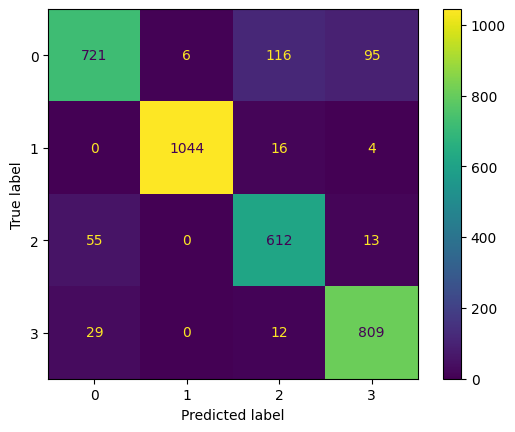

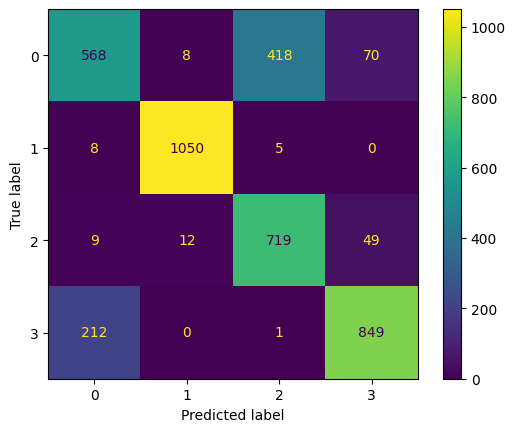

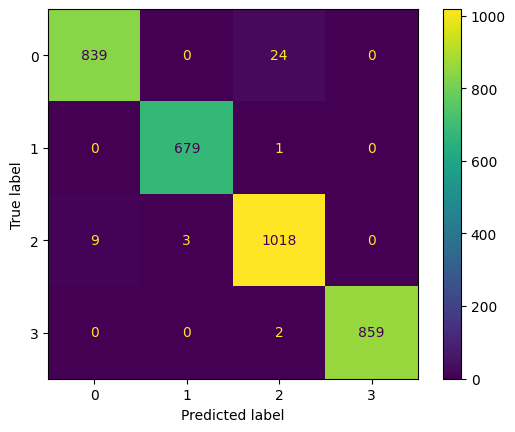

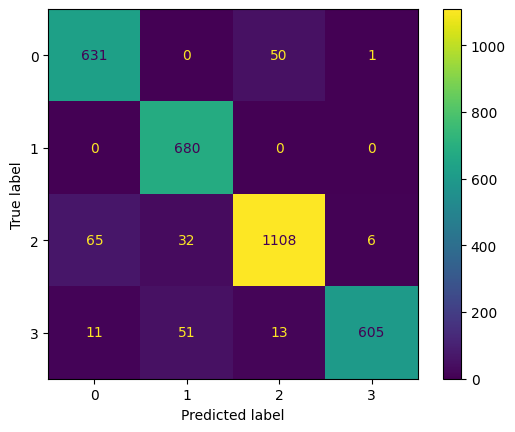

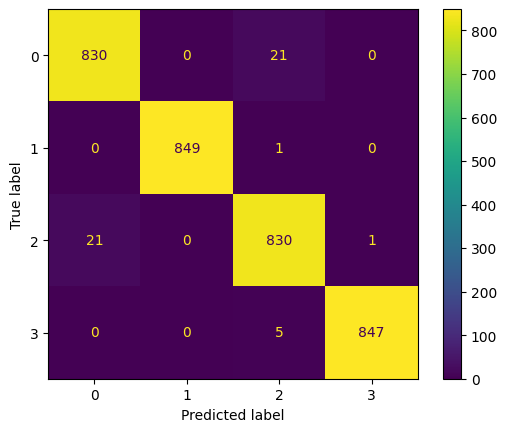

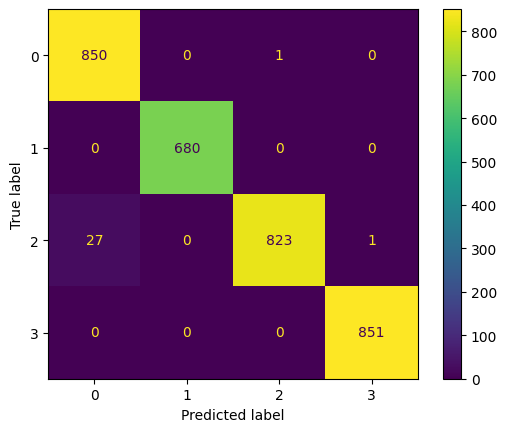

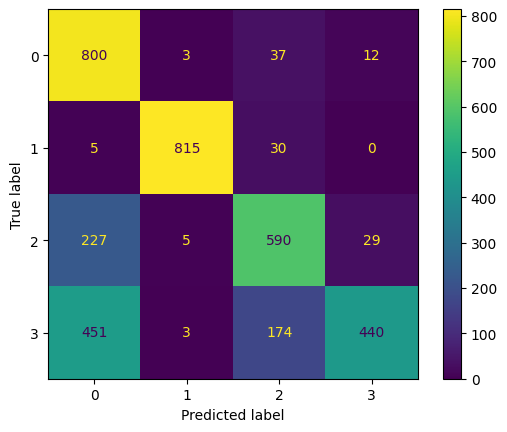

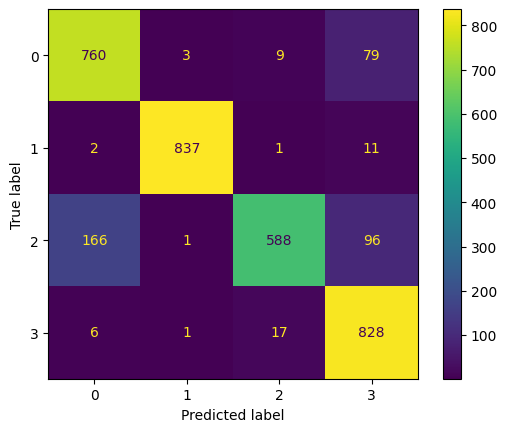

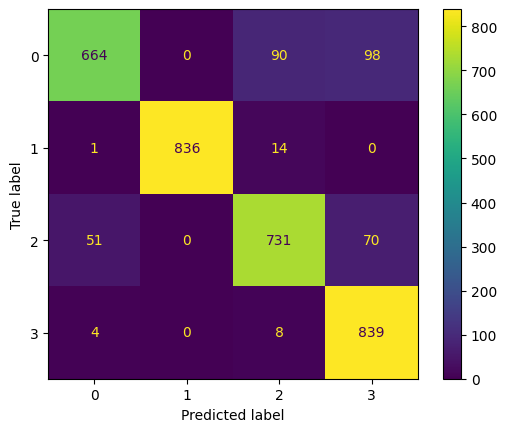

In [135]:
accuracies = []
for start_index,end_index in split_indices:
        print(f"************ Usando indices {start_index} e {end_index} como teste ******************* ")    
        X_train,y_train,X_validation,y_validation = create_validation_and_train_data(start_index,end_index)
        print (X_train)
        model  = cria_LSTM()
        model.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_validation, y_validation),use_multiprocessing=True,callbacks=[my_callbacks])  # Adjust epochs and batch size
        _, accuracy = model.evaluate(X_validation, y_validation)
        print(f"===============>Appending accuracy of {accuracy} ") 
        accuracies.append(accuracy)

        loss, accuracy = model.evaluate(X_validation, y_validation)
        predictions = model.predict(X_validation)
        print(y_validation)
        print(y_validation.shape)
        y_validation_inverse = np.argmax(y_validation, axis=1)
        print(y_validation_inverse)
        print(len(y_validation_inverse))
        print(predictions)
        classes_x=np.argmax(predictions,axis=1)
        print(classes_x)
        print(len(classes_x))
        print(classes_x.shape)
        from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
        cm = confusion_matrix(y_validation_inverse, classes_x)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm)
        disp.plot()
        print(classification_report(y_validation_inverse, classes_x))
print(f"Average accuracy: {np.mean(accuracies)}")

In [136]:
print(f"Average accuracy: {np.mean(accuracies)}")

Average accuracy: 0.901612917582194


In [ ]:
print(accuracies)